# Predikčná analýza: závažnosť zraniteľností

Notebook implementuje a porovnáva 2 algoritmy strojového učenia. Nadväzuje na `priprava_dat.ipynb`, ktorý musí byť spustený ako prvý.

**Cieľ.** Podľa textového popisu a typu CWE odhadnúť závažnosť novej zraniteľnosti ešte predtým, ako dostane skóre CVSS. Tím tak vie určiť, ktoré chyby riešiť prednostne.

| | |
| --- | --- |
| **Vstup** | `data/processed/cve_clean.csv`, záznamy s CVSS v3 |
| **Cieľ predikcie** | `severity_v3`: `LOW`, `MEDIUM`, `HIGH`, `CRITICAL` |
| **Vstupné znaky** | TF-IDF z `description`, typy z `cwe_ids` |
| **Modely** | logistická regresia, LightGBM, triviálny model ako spodná hranica |
| **Výstup** | tabuľka metrík, `figures/3_f1_podla_triedy.png`, `figures/4_matice_zamen.png` |

**Prevencia úniku informácií.** Vstupom nie je `cvss_v3`, `cvss_v2` ani žiadny stĺpec závažnosti, lebo cieľ sa zo skóre priamo počíta. Vstupom nie je ani rok ani identifikátor CVE.

## 1. Načítanie dát a odstránenie úniku cieľa

Prvý beh modelov ukázal, že medzi najsilnejšími znakmi sú frázy ako `integrity availability` a `difficult exploit`. Kontrola odhalila, že časť popisov priamo uvádza výsledok, ktorý má model predikovať, napríklad text `CVSS 3.1 Base Score 9.8` a vektor skóre, najmä v šablóne používanej v záznamoch Oracle. Iné popisy obsahujú vetu typu `rated as High severity`.

Takéto záznamy **vylučujeme z trénovania aj z testu**. Inak by model čítal odpoveď priamo z textu a výsledky by neplatili pre popisy bez skóre.

In [1]:
import time
from pathlib import Path

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap
from scipy import sparse
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    mean_absolute_error,
    precision_recall_fscore_support,
)

DATA_PATH = Path("data/processed/cve_clean.csv")
FIGURES_DIR = Path("figures")
LABELS = ["LOW", "MEDIUM", "HIGH", "CRITICAL"]
SEED = 42

LEAKAGE_PATTERN = (
    r"\bcvss(?:v?\d|:|\b)"
    r"|base score"
    r"|severity"
    r"|\brated\s+(?:as\s+)?(?:critical|high|moderate|medium|low)\b"
)

scored = pd.read_csv(DATA_PATH).dropna(subset=["severity_v3"])
has_leakage = scored["description"].str.contains(LEAKAGE_PATTERN, case=False, regex=True)
print(f"Záznamy s CVSS v3: {len(scored)}, vylúčené pre únik cieľa: {has_leakage.sum()}")

data = scored[~has_leakage].reset_index(drop=True)
data["cwe_text"] = data["cwe_ids"].fillna("")
data["target"] = pd.Categorical(data["severity_v3"], categories=LABELS, ordered=True).codes
assert data["target"].between(0, 3).all()

print(f"Záznamy použité v modelovaní: {len(data)}")
data[["cve_id", "year", "severity_v3", "cwe_text", "description"]].head(3)

Záznamy s CVSS v3: 92893, vylúčené pre únik cieľa: 4202
Záznamy použité v modelovaní: 88691


,cve_id,year,severity_v3,cwe_text,description
0,CVE-1999-0199,1999,CRITICAL,CWE-252,manual/search.texi in the GNU C Library (aka g...
1,CVE-1999-0236,1999,HIGH,CWE-200,ScriptAlias directory in NCSA and Apache httpd...
2,CVE-2000-0258,2000,HIGH,CWE-20,IIS 4.0 and 5.0 allows remote attackers to cau...


## 2. Rozdelenie dát

Rozdelenie je **časové**, aby test zodpovedal reálnemu použitiu, teda predikcii budúcich zraniteľností.

| Množina | Roky v CVE-ID | Použitie |
| --- | --- | --- |
| Tréningová | do 2018 | učenie pri ladení parametrov |
| Validačná | 2019 | výber parametrov |
| Testovacia | 2020 a 2021 | jednorazové záverečné vyhodnotenie |

Po výbere parametrov sa model naučí znova na všetkých dátach do roku 2019.

In [2]:
train = data[data["year"] <= 2018]
valid = data[data["year"] == 2019]
train_full = data[data["year"] <= 2019]
test = data[data["year"] >= 2020]

split_summary = pd.DataFrame({
    name: part["severity_v3"].value_counts(normalize=True).reindex(LABELS).mul(100).round(1)
    for name, part in {"tréning %": train, "validácia %": valid, "test %": test}.items()
})
split_summary.loc["počet záznamov"] = [len(train), len(valid), len(test)]
display(split_summary)

repeated_text = test["description"].isin(train_full["description"]).sum()
print(f"Testovacie záznamy s presne rovnakým popisom ako v tréningu: {repeated_text}")

,tréning %,validácia %,test %
severity_v3,,,
LOW,1.5,1.6,2.1
MEDIUM,38.2,39.4,41.2
HIGH,44.1,43.0,42.9
CRITICAL,16.2,16.0,13.8
počet záznamov,41890.0,14751.0,32050.0


Testovacie záznamy s presne rovnakým popisom ako v tréningu: 114


## 3. Príprava znakov

- **TF-IDF** premení popis na váhy slov a dvojíc slov. Slovník má najviac 30 000 položiek, výraz sa musí objaviť aspoň v 5 dokumentoch.
- **Typy CWE** sú binárne príznaky, jeden záznam môže mať viac typov.
- Slovník sa vždy učí **iba z tréningových dát**, aby sa do modelu nedostali informácie z testu.

In [3]:
def make_features():
    return ColumnTransformer([
        ("text", TfidfVectorizer(
            stop_words="english",
            ngram_range=(1, 2),
            min_df=5,
            max_df=0.9,
            max_features=30_000,
            sublinear_tf=True,
        ), "description"),
        ("cwe", CountVectorizer(
            lowercase=False,
            token_pattern=r"CWE-\d+",
            binary=True,
        ), "cwe_text"),
    ])

def to_float32(matrix):
    return sparse.csr_matrix(matrix, dtype=np.float32)

tuning_features = make_features()
X_train = to_float32(tuning_features.fit_transform(train))
X_valid = to_float32(tuning_features.transform(valid))
y_train, y_valid = train["target"].to_numpy(), valid["target"].to_numpy()
print("Rozmer tréningovej matice:", X_train.shape)

Rozmer tréningovej matice: (41890, 30182)


## 4. Implementované algoritmy

**Logistická regresia** je lineárny model. Každé slovo má pre každú triedu jednu váhu, preto je rýchla a dobre vysvetliteľná.

**LightGBM** je gradient boosting nad rozhodovacími stromami. Stromy sa stavajú postupne a každý opravuje chyby predchádzajúcich, takže model zachytí aj kombinácie znakov.

Oba modely používajú `class_weight="balanced"`, aby málo početná trieda `LOW` nebola prehliadnutá. Parametre sa vyberajú podľa **macro F1** na validačnej množine. LightGBM navyše určuje počet stromov cez skoré zastavenie.

In [4]:
def macro_f1(y_true, y_pred):
    return f1_score(y_true, y_pred, average="macro", labels=[0, 1, 2, 3], zero_division=0)

def make_logreg(C):
    return LogisticRegression(C=C, class_weight="balanced", max_iter=2000, random_state=SEED)

logreg_results = []
for C in [0.3, 1, 3, 10]:
    model = make_logreg(C).fit(X_train, y_train)
    logreg_results.append({"C": C, "macro F1": macro_f1(y_valid, model.predict(X_valid))})

logreg_results = pd.DataFrame(logreg_results).round(4)
best_C = logreg_results.loc[logreg_results["macro F1"].idxmax(), "C"]
display(logreg_results)
print("Najlepšie C:", best_C)

,C,macro F1
0,0.3,0.4924
1,1.0,0.5055
2,3.0,0.5062
3,10.0,0.4928


Najlepšie C: 3.0


In [5]:
def make_lightgbm(num_leaves, n_estimators):
    return lgb.LGBMClassifier(
        objective="multiclass",
        class_weight="balanced",
        n_estimators=n_estimators,
        learning_rate=0.1,
        num_leaves=num_leaves,
        min_child_samples=20,
        colsample_bytree=0.3,
        subsample=0.8,
        subsample_freq=1,
        random_state=SEED,
        deterministic=True,
        force_row_wise=True,
        n_jobs=4,
        verbosity=-1,
    )

lightgbm_results = []
for num_leaves in [31, 63]:
    model = make_lightgbm(num_leaves, n_estimators=500)
    model.fit(
        X_train, y_train,
        eval_X=X_valid,
        eval_y=y_valid,
        eval_metric="multi_logloss",
        callbacks=[lgb.early_stopping(30, verbose=False)],
    )
    lightgbm_results.append({
        "num_leaves": num_leaves,
        "počet stromov": model.best_iteration_,
        "macro F1": macro_f1(y_valid, model.predict(X_valid)),
    })

lightgbm_results = pd.DataFrame(lightgbm_results).round(4)
best_lightgbm = lightgbm_results.loc[lightgbm_results["macro F1"].idxmax()]
best_leaves, best_trees = int(best_lightgbm["num_leaves"]), int(best_lightgbm["počet stromov"])
display(lightgbm_results)
print("Najlepšie num_leaves:", best_leaves, "počet stromov:", best_trees)

,num_leaves,počet stromov,macro F1
0,31,209,0.5123
1,63,118,0.5169


Najlepšie num_leaves: 63 počet stromov: 118


## 5. Záverečné učenie a vyhodnotenie na testovacích dátach

Modely sa naučia na všetkých dátach do roku 2019 a testovacia množina sa použije iba raz.

In [6]:
final_features = make_features()
X_full = to_float32(final_features.fit_transform(train_full))
X_test = to_float32(final_features.transform(test))
y_full, y_test = train_full["target"].to_numpy(), test["target"].to_numpy()

models = {
    "Triviálny model": DummyClassifier(strategy="most_frequent"),
    "Logistická regresia": make_logreg(best_C),
    "LightGBM": make_lightgbm(best_leaves, best_trees),
}

predictions, fit_seconds = {}, {}
for name, model in models.items():
    started = time.perf_counter()
    model.fit(X_full, y_full)
    fit_seconds[name] = time.perf_counter() - started
    predictions[name] = model.predict(X_test)

### Použité metriky

| Metrika | Čo meria |
| --- | --- |
| **Macro F1** | hlavná metrika, priemer F1 všetkých tried, každá trieda má rovnakú váhu |
| **Accuracy** | podiel správnych predikcií, pri nevyvážených triedach môže klamať |
| **Vážené F1** | F1 vážené početnosťou tried |
| **MAE poradia** | priemerná vzdialenosť tried, `LOW` = 0 až `CRITICAL` = 3, menej je lepšie |
| **Recall a precision `CRITICAL`** | koľko kritických model zachytí a ako často je jeho poplach správny |

In [7]:
CRITICAL = LABELS.index("CRITICAL")

def evaluate(y_true, y_pred):
    precision, recall, _, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=[CRITICAL], zero_division=0
    )
    return {
        "Macro F1": macro_f1(y_true, y_pred),
        "Accuracy": accuracy_score(y_true, y_pred),
        "Vážené F1": f1_score(y_true, y_pred, average="weighted", zero_division=0),
        "MAE poradia": mean_absolute_error(y_true, y_pred),
        "Recall CRITICAL": recall[0],
        "Precision CRITICAL": precision[0],
    }

metrics = pd.DataFrame({name: evaluate(y_test, pred) for name, pred in predictions.items()}).T
metrics["Tréning (s)"] = pd.Series(fit_seconds)
metrics.round(3)

,Macro F1,Accuracy,Vážené F1,MAE poradia,Recall CRITICAL,Precision CRITICAL,Tréning (s)
Triviálny model,0.150,0.429,0.258,0.592,0.000,0.000,0.001
Logistická regresia,0.505,0.640,0.647,0.415,0.666,0.430,6.587
LightGBM,0.508,0.647,0.654,0.411,0.726,0.432,35.818


In [8]:
per_class = pd.concat({
    name: pd.DataFrame(
        precision_recall_fscore_support(y_test, predictions[name], labels=[0, 1, 2, 3], zero_division=0)[:3],
        index=["precision", "recall", "F1"],
        columns=LABELS,
    ).T
    for name in ["Logistická regresia", "LightGBM"]
})
display(per_class.round(3))

# Spoľahlivosť rozdielu: bootstrap testovacej množiny
rng = np.random.default_rng(SEED)
def critical_recall(y_true, y_pred):
    return (y_pred[y_true == CRITICAL] == CRITICAL).mean()

differences = {"macro F1": [], "recall CRITICAL": []}
for _ in range(300):
    sample = rng.integers(0, len(y_test), len(y_test))
    y_sample = y_test[sample]
    pred_lightgbm = predictions["LightGBM"][sample]
    pred_logreg = predictions["Logistická regresia"][sample]
    differences["macro F1"].append(macro_f1(y_sample, pred_lightgbm) - macro_f1(y_sample, pred_logreg))
    differences["recall CRITICAL"].append(critical_recall(y_sample, pred_lightgbm) - critical_recall(y_sample, pred_logreg))

for metric, values in differences.items():
    low, high = np.percentile(values, [2.5, 97.5])
    print(f"Rozdiel {metric} (LightGBM mínus logistická regresia): {np.mean(values):.4f}, 95 % interval [{low:.4f}, {high:.4f}]")

precision  recall     F1
Logistická regresia LOW           0.124   0.147  0.134
                    MEDIUM        0.761   0.678  0.717
                    HIGH          0.674   0.619  0.645
                    CRITICAL      0.430   0.666  0.522
LightGBM            LOW           0.123   0.114  0.118
                    MEDIUM        0.775   0.673  0.720
                    HIGH          0.684   0.623  0.652
                    CRITICAL      0.432   0.726  0.542

Rozdiel macro F1 (LightGBM mínus logistická regresia): 0.0034, 95 % interval [-0.0025, 0.0101]
Rozdiel recall CRITICAL (LightGBM mínus logistická regresia): 0.0601, 95 % interval [0.0472, 0.0735]


## 6. Vizualizácie výsledkov

In [9]:
SURFACE = "#fcfcfb"
INK = "#0b0b0b"
INK_SECONDARY = "#52514e"
GRID = "#e1e0d9"
AXIS = "#c3c2b7"
MODEL_COLORS = {"Logistická regresia": "#2a78d6", "LightGBM": "#eb6834"}

plt.rcParams.update({
    "font.family": ["Segoe UI", "DejaVu Sans"],
    "font.size": 10,
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "axes.edgecolor": AXIS,
    "axes.labelcolor": INK_SECONDARY,
    "axes.titlecolor": INK,
    "text.color": INK,
    "xtick.color": INK_SECONDARY,
    "ytick.color": INK_SECONDARY,
    "savefig.dpi": 160,
    "savefig.bbox": "tight",
    "savefig.facecolor": SURFACE,
})
FIGURES_DIR.mkdir(exist_ok=True)

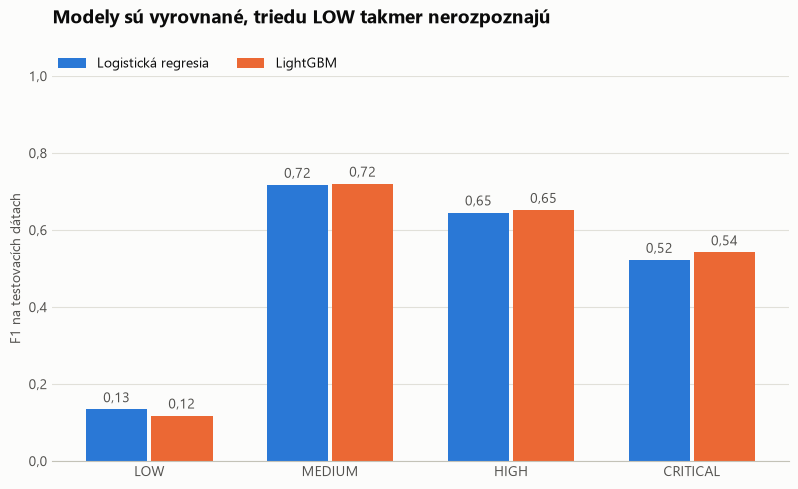

In [10]:
fig, ax = plt.subplots(figsize=(9.5, 5))
positions = np.arange(len(LABELS))
width = 0.36

for offset, name in zip((-width / 2, width / 2), MODEL_COLORS):
    values = per_class.loc[name, "F1"].reindex(LABELS).to_numpy()
    bars = ax.bar(positions + offset, values, width - 0.02, color=MODEL_COLORS[name], label=name)
    ax.bar_label(bars, labels=[f"{value:.2f}".replace(".", ",") for value in values],
                 padding=3, color=INK_SECONDARY)

ax.spines[["top", "right", "left"]].set_visible(False)
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.tick_params(length=0)
ax.set_xticks(positions, LABELS)
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(lambda value, _: f"{value:.1f}".replace(".", ","))
ax.set_ylabel("F1 na testovacích dátach")
ax.set_title('Modely sú vyrovnané, triedu LOW takmer nerozpoznajú', loc="left", fontsize=14, fontweight="bold", pad=38)
ax.legend(ncols=2, frameon=False, loc="lower left", bbox_to_anchor=(0, 1.0), borderaxespad=0)

fig.savefig(FIGURES_DIR / "3_f1_podla_triedy.png")
plt.show()

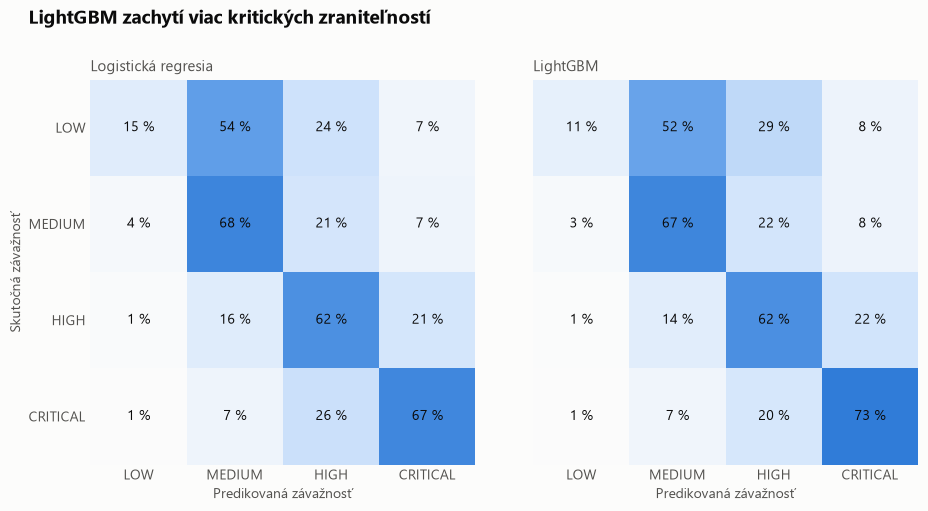

In [11]:
blues = LinearSegmentedColormap.from_list("blues", ["#fcfcfb", "#cde2fb", "#6da7ec", "#2a78d6", "#104281"])
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharey=True, gridspec_kw={"wspace": 0.08})

for ax, name in zip(axes, MODEL_COLORS):
    matrix = confusion_matrix(y_test, predictions[name], labels=[0, 1, 2, 3], normalize="true")
    ax.imshow(matrix, cmap=blues, vmin=0, vmax=1)
    for row in range(4):
        for column in range(4):
            value = matrix[row, column]
            ax.text(column, row, f"{value * 100:.0f} %", ha="center", va="center",
                    color="#ffffff" if value >= 0.75 else INK)
    ax.set_title(name, loc="left", fontsize=11, color=INK_SECONDARY)
    ax.set_xticks(range(4), LABELS)
    ax.set_yticks(range(4), LABELS)
    ax.set_xlabel("Predikovaná závažnosť")
    ax.tick_params(length=0)
    ax.spines[:].set_visible(False)

axes[0].set_ylabel("Skutočná závažnosť")
fig.suptitle('LightGBM zachytí viac kritických zraniteľností', x=0.08, y=1.02, ha="left", fontsize=14, fontweight="bold")

fig.savefig(FIGURES_DIR / "4_matice_zamen.png")
plt.show()

## 7. Čo modely považujú za dôležité

In [12]:
names = final_features.get_feature_names_out()
logreg = models["Logistická regresia"]
booster = models["LightGBM"]

top_words = pd.DataFrame({
    label: names[np.argsort(logreg.coef_[index])[::-1][:12]]
    for index, label in enumerate(LABELS)
})
print("Znaky s najvyššou váhou v logistickej regresii podľa triedy:")
display(top_words)

gain = pd.Series(booster.booster_.feature_importance(importance_type="gain"), index=names)
print("Znaky s najvyšším prínosom v LightGBM:")
gain.sort_values(ascending=False).head(15).round(0).to_frame("gain")

Znaky s najvyššou váhou v logistickej regresii podľa triedy:


,LOW,MEDIUM,HIGH,CRITICAL
0,text__ibm,text__xss,text__impact crafted,text__unauthenticated
1,text__local,text__authenticated,text__gain privileges,text__code
2,text__confidentiality vectors,text__users cause,text__privileges,text__execution
3,text__sec,text__crafted file,text__users gain,text__possibly
4,text__cpanel,text__crafted,text__execution vulnerability,text__gain
5,text__eva,text__dissector wireshark,text__code execution,text__execute
6,text__memory exhaustion,text__physical access,text__execute,text__credentials
7,text__libwebp,text__display,text__privilege,text__information cause
8,text__timing,text__privilege execution,text__arbitrary code,text__password
9,text__crafted app,text__local information,text__sensitive information,text__code cause


Znaky s najvyšším prínosom v LightGBM:


,gain
cwe__CWE-79,24434.0
text__information,13882.0
text__code,12041.0
text__xss,6546.0
cwe__CWE-200,6517.0
text__local,6200.0
text__cross site,5379.0
cwe__CWE-89,5353.0
text__execute arbitrary,4836.0
text__arbitrary code,4802.0


## 8. Zhrnutie a odporúčanie

Výsledky platia pre testovaciu množinu 32 050 zraniteľností z rokov 2020 a 2021. Modely sa učili na dátach do roku 2019.

| Metrika | Triviálny model | Logistická regresia | LightGBM |
| --- | ---: | ---: | ---: |
| Macro F1 | 0,150 | 0,505 | 0,508 |
| Accuracy | 0,429 | 0,640 | 0,647 |
| Vážené F1 | 0,258 | 0,647 | 0,654 |
| MAE poradia | 0,592 | 0,415 | 0,411 |
| Recall `CRITICAL` | 0,000 | 0,666 | 0,726 |
| Precision `CRITICAL` | 0,000 | 0,430 | 0,432 |
| Čas tréningu | menej ako 1 s | 7 s | 36 s |

**Vyhodnotenie:**

- Oba modely jasne prekonali triviálny model, takže popis a typ CWE nesú užitočnú informáciu o závažnosti.
- V hlavnej metrike sú modely vyrovnané. Rozdiel macro F1 je 0,003 v prospech LightGBM a jeho 95 % interval [-0,003; 0,010] obsahuje nulu.
- Spoľahlivý rozdiel je pri kritických zraniteľnostiach. LightGBM ich zachytí o 6,0 percentuálneho bodu viac, interval je [4,7; 7,4] bodu, a to pri rovnakej presnosti.
- Trieda `LOW` je slabá pri oboch modeloch, F1 je približne 0,12 až 0,13. Tvorí len asi 2 % dát a v popisoch sa málo odlišuje od `MEDIUM`.

**Odporúčanie: LightGBM**, ak je cieľom určiť, ktoré zraniteľnosti riešiť prednostne, lebo zachytí viac kritických prípadov. Logistická regresia je vhodná, keď je dôležitejšia rýchlosť a jednoduché vysvetlenie.

**Vplyv odstránenia úniku cieľa.** Pred vylúčením 4 202 záznamov mali modely macro F1 0,529 a 0,544 a LightGBM pôsobil jasne lepšie. Po ich vylúčení sa skóre znížilo a rozdiel v macro F1 prestal byť preukázateľný. Testovacie množiny v oboch behoch nie sú rovnaké, porovnanie je preto orientačné.

**Obmedzenia:**

- Precision `CRITICAL` je približne 0,43, takže viac ako polovica označených zraniteľností v skutočnosti kritická nie je. Model je vhodný na predbežné triedenie, nie ako náhrada odborného posúdenia.
- Približne 8 % skutočne kritických zraniteľností oba modely zaradia len do `LOW` alebo `MEDIUM`.
- Závažnosť CVSS nie je to isté ako pravdepodobnosť skutočného zneužitia.
- Vzorec na hľadanie úniku zachytí explicitné uvedenie skóre, no nevylučuje všetky nepriame opisy dopadu.
- Prehľadané boli len malé mriežky parametrov, intenzívnejšie ladenie alebo textové transformery môžu výsledky zmeniť.
- Bootstrap zachytáva iba náhodnosť výberu testovacích záznamov, nie zmenu dát v čase.